# Experiment: X-TRACK (xLSTM + GAT + kinematics)

X-TRACK (2025; [code](https://github.com/archugh02/X-TRACK)): an sLSTM (xLSTM's scalar-memory cell with exponential gating) encodes each vehicle, two graph attention layers model interaction, an LSTM decoder predicts longitudinal acceleration and yaw rate, and a kinematic layer integrates them into positions; a kinematic loss (weight 0.1) supervises the predicted controls.

Part of the model comparison in `experiments/MODEL_ALTERNATIVES.md`. Run All; set `DEBUG = False` in section 2 for the real run.

## 0. Decisions & assumptions

Every choice that could change the result is listed here; the cell notes below repeat the ones that apply to each cell.

**Shared by every notebook (S)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| S1 | Same data for every model: NGSIM us-101 + i-80 (DEBUG: first 250k rows of us-101), scene-level 70/10/20 split, seed 42, train-only normalization. | Differences in the results must come from the model, not the data. | Papers use their own splits, so published numbers are not like-for-like with ours. |
| S2 | Same training budget for every model: config.py defaults (12 epochs, Adam lr 5e-4 decayed x0.6 per epoch, batch 128, weight decay 1e-5, grad clip 1.0). | A fair comparison; per-model tuning would favour whichever model got tuned most. | Each paper's own schedule (e.g. CS-LSTM trains longer with lr 1e-3). Tune later with --mode tune if a model looks under-trained. |
| S3 | Loss = MSE + bivariate-Gaussian NLL + neighbour-goal MSE (`basic_loss`); the risk-scaled loss is used only where this notebook's M table says so (STRAP-R-based variants). Models without a goal head output zero goals, so their goal term is a constant. A model may add its own `aux_loss` (only the diffusion model does). | Keeps one training objective; the risk-scaled loss is STRAP-R's own contribution. | Loss values are therefore not comparable across models: compare RMSE only. |
| S4 | Best checkpoint = lowest validation loss (`fit` default); test RMSE is reported at 1-5 s for that checkpoint. | Same selection rule for every model. | Selecting on val RMSE would be closer to the reported metric. |
| S5 | KNOWN LIMITATION (not fixed): positions are relative to the target at each timestep, so the target's own history is always (0, 0) and lateral speed is always 0 (NGSIM gives longitudinal speed only). The target is seen through speed, acceleration and lane features; lateral context comes from neighbours. | Kept as is (user decision) so every model gets identical inputs. | Papers feed the target's own x/y track; lane-change prediction is handicapped for all models here. |
| S6 | Neighbours = up to 15 risk-selected vehicles (S/O-field > RISK_THRESHOLD), not every nearby vehicle. | Same scene construction as STRAP. | Grid/graph papers use all vehicles in range; ours see only the risk-selected ones. |
| S7 | Output = one bivariate Gaussian per future step (mu_x, mu_y, sigma_x, sigma_y, rho); RMSE uses the mean. Multimodal models are moment-matched to one Gaussian. | The `fit` / `evaluate_trajectory` contract and how STRAP's Table I is scored. | minADE/minFDE over modes would favour multimodal models. |

**Specific to this model (M)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| M1 | sLSTM cell written in plain PyTorch: exponential input/forget gates with the max-stabiliser state and normaliser, as in the xLSTM paper. | No xLSTM package needed. | X-TRACK's code may use the official xLSTM blocks (with up-projections). |
| M2 | Inputs: all 11 features (same contract). | X-TRACK uses acceleration and yaw-rate histories; we have acceleration but no yaw rate (S5). | - |
| M3 | 2 GAT layers over real vehicles; decoder LSTM(128) fed context every step; outputs a, yaw rate, sigma_x, sigma_y, rho per step. | Paper layout. | - |
| M4 | Kinematic layer: a = 6 tanh, yaw rate = 0.4 tanh, integrated from the last speed, heading 0 (as `strap_kinematic`). | X-TRACK bounds controls physically. | ASSUMPTION: bounds are ours. |
| M5 | Kinematic loss via `aux_loss`: 0.1 x MSE between predicted controls and controls derived from the true future (finite differences). | X-TRACK's 0.1-weighted kinematic term. | NGSIM finite-difference controls are noisy; the weight keeps them a weak guide. |

## 1. Setup

**Decisions in this cell:** seed fixed to `SEED` (42) in every notebook so initialisation is not a source of differences (S1).

In [1]:
import sys
from pathlib import Path

# Repo root = first folder upwards that contains src/ (works from experiments/ or the root).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import time
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from src.config import (
    BATCH_SIZE, BETA_LOSS, DEBUG_MAX_ROWS, DEVICE, DROPOUT, DT, LEARNING_RATE, LR_DECAY, N_V,
    NGSIM_LOCATIONS, NUM_EPOCHS, NORMALIZATION_FILE, SEED, STATE_DIM, TF_STEPS, TH_STEPS, WEIGHT_DECAY,
)
from src.data.loader import NGSIMDataLoader, create_dataloader
from src.data.normalization import load_stats, normalize_samples
from src.evaluation.evaluate import evaluate_trajectory
from src.models.strap import STRAP
from src.pipeline import collision_scores, metric_rows, test_groups
from src.train import fit, prepare_data
from experiments.benchmark import compare, save_result

torch.manual_seed(SEED)
print("device:", DEVICE)

/home/st_students/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


device: cuda


## 2. Experiment config

**Decisions in this cell:** training budget is config.py's (S2); `use_risk_loss` as in the M table; collisions scored at 2 m like `--mode collisions`.

In [2]:
EXP_NAME = "x_track"          # unique per notebook -> experiments/results/<EXP_NAME>.json
DESCRIPTION = "X-TRACK: sLSTM encoders + 2 GAT layers, decodes acceleration/yaw rate through a kinematic layer"

DEBUG = False                  # True: DEBUG_MAX_ROWS of us-101 for a quick check; False: full data
LOCATIONS = ["us-101"] if DEBUG else NGSIM_LOCATIONS

HPARAMS = dict(               # keyword args of src.train.fit
    num_epochs=NUM_EPOCHS,
    use_risk_loss=False,       # False = basic loss (STRAP-B style)
    beta=BETA_LOSS,
    learning_rate=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    lr_decay=LR_DECAY,
    weight_decay=WEIGHT_DECAY,
)

RUN_COLLISIONS = False         # per-pair collision scoring on the test split (slow on full data)
COLLISION_THRESHOLD = 2.0     # metres, GT collision label distance

CKPT_DIR = ROOT / "experiments" / "checkpoints" / EXP_NAME

## 3. Data
Train-only normalization stats and the intention codebook are written to `CKPT_DIR`.

**Decisions in this cell:** same loader, split and train-only normalization as every other notebook (S1, S6); `norm_stats` is loaded here so the model (next section) can recover metres and lane numbers.

In [3]:
loader = NGSIMDataLoader(locations=LOCATIONS, max_rows=DEBUG_MAX_ROWS if DEBUG else None)
train_s, val_s, centers = prepare_data(loader, save_dir=str(CKPT_DIR))
_, _, test_raw = loader.get_splits()   # cached; raw (unnormalized) test split
# Train-only mean/std; models that need metres or lane numbers undo the normalization with it.
norm_stats = load_stats(str(CKPT_DIR / NORMALIZATION_FILE))
print(f"train/val/test = {len(train_s)}/{len(val_s)}/{len(test_raw)}")

2026-10-31 05:32:00,680 - STRAP - INFO - [NGSIMLoader] Loading cached data from /home/st_students/MTP/data/raw/ngsim/ngsim_us-101.csv


2026-10-31 05:32:08,149 - STRAP - INFO - [NGSIMLoader] Dropping 704,000 duplicate rows (0 duplicate groups differ in other columns)


2026-10-31 05:32:08,959 - STRAP - INFO - [NGSIMLoader] 'us-101' period 1: 1,180,598 rows, frame_id offset=0


2026-10-31 05:32:08,987 - STRAP - INFO - [NGSIMLoader] 'us-101' period 2: 1,403,095 rows, frame_id offset=9609


2026-10-31 05:32:09,016 - STRAP - INFO - [NGSIMLoader] 'us-101' period 3: 1,515,240 rows, frame_id offset=19680


...

2026-10-31 05:49:42,746 - STRAP - INFO - [Train] Fitting k-means intention codebook on training data...


/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


2026-10-31 05:50:11,746 - STRAP - INFO - [Train] Saved intention codebook ((100, 4)) to /home/st_students/MTP/experiments/checkpoints/x_track/intention_clusters.pkl


2026-10-31 05:50:13,282 - STRAP - INFO - [NGSIMLoader] Per-recording temporal split over 6 recordings: train=540149 {'i-80': 287507, 'us-101': 252642}, val=86077 {'i-80': 50059, 'us-101': 36018}, test=121130 {'i-80': 58995, 'us-101': 62135}


train/val/test = 540149/86077/121130


## 4. Model

Any `torch.nn.Module` works if `forward(states, mask, dims)` returns a 3-tuple:

| output | shape | meaning |
|---|---|---|
| `traj_dist` | `(B, T_f=50, 5)` | `[mu_x, mu_y, sigma_x, sigma_y, rho]` of the target, metres relative to its last observed position (x longitudinal, y lateral); `sigma > 0`, `rho` in (-1, 1) |
| `goals` | `(B, N-1, 4)` | neighbour goals; a model without a goal head returns `states.new_zeros(B, N - 1, 4)` |
| third | anything | ignored by training/eval (STRAP returns its risk field) |

Inputs: `states (B, T_h=30, N, 11)` normalized (vehicle 0 = target, rest neighbours, zero-padded),
`mask (B, N)` True = real vehicle, `dims (B, N, 2)` raw length/width in metres.
Feature index: 0 rel-longitudinal m, 1 rel-lateral m, 2 speed/30, 3 lateral speed (always 0), 4 accel/10,
5 type/2, 6 relative lane (target - vehicle, left = +), 7 length/10, 8 width/3, 9 S-field risk, 10 O-field risk.
Raw value = `states * std + mean` with `norm_stats`. STRAP's k-means codebook is only loaded if the model has a `risk_decoder`.

**Decisions in this cell:** sLSTM encoder (M1), GAT interaction (M3), control decoder + kinematic layer (M4), kinematic loss (M5). Built after the data cell because it needs `norm_stats`.

In [4]:
class GATLayer(nn.Module):
    """Single-head graph attention over real vehicles (fully connected graph)."""
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W = nn.Linear(d_in, d_out, bias=False)
        self.a_src = nn.Linear(d_out, 1, bias=False)
        self.a_dst = nn.Linear(d_out, 1, bias=False)

    def forward(self, x, mask):                                     # x (B, N, d_in)
        h = self.W(x)
        e = F.leaky_relu(self.a_dst(h) + self.a_src(h).transpose(1, 2), 0.2)   # (B, N, N)
        e = e.masked_fill(~mask[:, None, :], float("-inf"))
        return F.elu(torch.softmax(e, dim=-1) @ h)

def kinematic_rollout(accel, yaw_rate, v0, dt=DT):
    """Integrate (..., T) acceleration and yaw rate from speed v0 (...) and heading 0 -> (..., T, 2)."""
    speed = (v0[..., None] + torch.cumsum(accel, dim=-1) * dt).clamp(min=0)
    heading = torch.cumsum(yaw_rate, dim=-1) * dt
    return torch.stack([torch.cumsum(speed * heading.cos(), -1), torch.cumsum(speed * heading.sin(), -1)], -1) * dt


def controls_from_positions(gt, v0, dt=DT):
    """Acceleration and yaw rate (B, T) implied by a (B, T, 2) future that starts at the origin with speed v0, heading 0."""
    steps = torch.diff(gt, dim=1, prepend=torch.zeros_like(gt[:, :1]))
    speed = steps.norm(dim=-1) / dt
    heading = torch.atan2(steps[..., 1], steps[..., 0].clamp(min=1e-3))
    accel = torch.diff(speed, dim=1, prepend=v0[:, None]) / dt
    yaw_rate = torch.diff(heading, dim=1, prepend=torch.zeros_like(heading[:, :1])) / dt
    return accel, yaw_rate

A_MAX, YAW_RATE_MAX = 6.0, 0.4


class SLSTMCell(nn.Module):
    """xLSTM scalar-memory cell (exponential gating with stabiliser m and normaliser n)."""
    def __init__(self, d_in, d):
        super().__init__()
        self.W, self.R = nn.Linear(d_in, 4 * d), nn.Linear(d, 4 * d, bias=False)

    def forward(self, x):                                           # x (B, T, d_in)
        B, T, _ = x.shape
        d = self.R.in_features
        h = c = x.new_zeros(B, d)
        n, m = x.new_ones(B, d), x.new_zeros(B, d)
        wx = self.W(x)
        for t in range(T):
            z, i, f, o = (wx[:, t] + self.R(h)).chunk(4, -1)
            m_new = torch.maximum(f + m, i)
            i, f = torch.exp(i - m_new), torch.exp(f + m - m_new)
            c = f * c + i * torch.tanh(z)
            n = f * n + i
            h = torch.sigmoid(o) * c / n
            m = m_new
        return h


class XTrack(nn.Module):
    def __init__(self, norm_stats, d=64, dec=128, T_f=TF_STEPS):
        super().__init__()
        self.register_buffer("mean", torch.tensor(norm_stats["mean"]))
        self.register_buffer("std", torch.tensor(norm_stats["std"]))
        self.T_f = T_f
        self.embed = nn.Linear(STATE_DIM, 32)
        self.slstm = SLSTMCell(32, d)
        self.gat1, self.gat2 = GATLayer(d, d), GATLayer(d, d)
        self.decoder = nn.LSTM(2 * d, dec, batch_first=True)
        self.head = nn.Linear(dec, 5)

    def controls(self, states, mask):
        B, T_h, N, _ = states.shape
        h = self.slstm(F.elu(self.embed(states.transpose(1, 2).reshape(B * N, T_h, -1)))).reshape(B, N, -1)
        g = self.gat2(self.gat1(h, mask), mask)
        out, _ = self.decoder(torch.cat([h[:, 0], g[:, 0]], -1)[:, None].expand(-1, self.T_f, -1))
        out = self.head(out)
        return A_MAX * torch.tanh(out[..., 0]), YAW_RATE_MAX * torch.tanh(out[..., 1]), out

    def speed0(self, states):
        return (states[:, -1, 0, 2] * self.std[2] + self.mean[2]) * 30.0

    def forward(self, states, mask, dims=None):
        B, _, N, _ = states.shape
        accel, yaw_rate, out = self.controls(states, mask)
        xy = kinematic_rollout(accel, yaw_rate, self.speed0(states))
        traj = torch.cat([xy, F.softplus(out[..., 2:4]) + 1e-3, torch.tanh(out[..., 4:5])], -1)
        return traj, states.new_zeros(B, N - 1, 4), None

    def aux_loss(self, states, mask, dims, gt):                     # M5
        accel, yaw_rate, _ = self.controls(states, mask)
        a_true, w_true = controls_from_positions(gt, self.speed0(states))
        return 0.1 * (F.mse_loss(accel, a_true.clamp(-A_MAX, A_MAX)) + F.mse_loss(yaw_rate, w_true.clamp(-YAW_RATE_MAX, YAW_RATE_MAX)))


def build_model():
    return XTrack(norm_stats)

model = build_model().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"{type(model).__name__}: {n_params:,} parameters")

XTrack: 166,405 parameters


## 5. Train

**Decisions in this cell:** `fit` with the config budget (S2); best checkpoint by val loss (S4). Loss curves are only comparable within this notebook (S3).

2026-10-31 05:50:14,116 - STRAP - INFO - Training STRAP on cuda


2026-10-31 05:50:14,116 - STRAP - INFO - Epochs: 12, Risk Loss: False, Beta: 0.0, LR: 0.0005, Batch: 128, LR decay: 0.6, Weight decay: 1e-05


2026-10-31 05:50:14,117 - STRAP - INFO - Number of training batches: 4220


2026-10-31 05:50:14,117 - STRAP - INFO - Number of validation batches: 673


2026-10-31 05:54:58,840 - STRAP - INFO - Epoch 1/12: Train Loss=606.8246 (goal=598.7877, traj=7.6572), Val Loss=391.6857, Val RMSE=2.1826


...

2026-10-31 06:42:55,107 - STRAP - INFO - Epoch 11/12: Train Loss=604.9745 (goal=598.7872, traj=5.8174), Val Loss=390.8907, Val RMSE=2.0494


2026-10-31 06:42:55,110 - STRAP - INFO -   -> Saved best checkpoint (val_loss=390.8907)


2026-10-31 06:47:44,018 - STRAP - INFO - Epoch 12/12: Train Loss=604.9719 (goal=598.7872, traj=5.8148), Val Loss=390.9024, Val RMSE=2.0516


2026-10-31 06:47:44,032 - STRAP - INFO - Training complete!


,epoch,train_loss,goal_loss,traj_loss,val_loss,val_rmse,lr
0,1,606.824636,598.787745,7.657246,391.685654,2.182613,0.000300
1,2,605.562576,598.785466,6.401340,391.252952,2.106627,0.000180
2,3,605.316542,598.787494,6.155900,391.081726,2.082324,0.000108
3,4,605.171925,598.787669,6.012694,391.005729,2.067478,0.000065
4,5,605.090127,598.784902,5.934480,390.959929,2.060813,0.000039
5,6,605.042496,598.786263,5.885907,391.007914,2.072331,0.000023
6,7,605.014434,598.786342,5.857985,390.935710,2.057034,0.000014
7,8,604.996436,598.787068,5.839345,390.924177,2.054845,0.000008
8,9,604.988767,598.790900,5.827944,390.922159,2.055779,0.000005
9,10,604.978782,598.787466,5.821414,390.952178,2.061838,0.000003


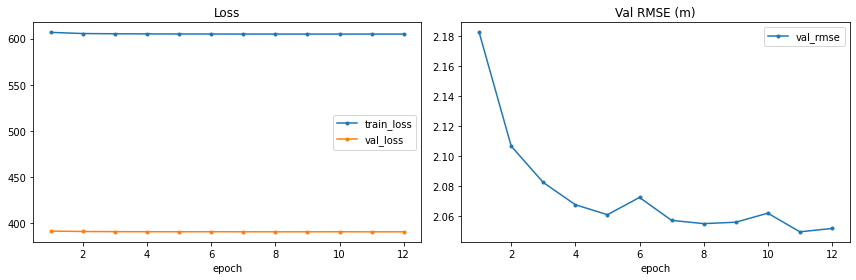

In [5]:
t0 = time.time()
training_log = fit(model, train_s, val_s, centers, save_dir=str(CKPT_DIR), **HPARAMS)
train_minutes = (time.time() - t0) / 60

log_df = pd.DataFrame(training_log)
display(log_df)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
log_df.plot(x="epoch", y=["train_loss", "val_loss"], marker=".", ax=axes[0], title="Loss")
log_df.plot(x="epoch", y="val_rmse", marker=".", ax=axes[1], title="Val RMSE (m)")
plt.tight_layout(); plt.show()

## 6. Evaluate (best checkpoint) — RMSE 1s…5s overall, per site, zero-neighbour scenes

**Decisions in this cell:** RMSE of the predicted mean at 1-5 s on the test split, overall / per site / target-only scenes (S7).

In [6]:
model.load_state_dict(torch.load(CKPT_DIR / "best_model.pt", map_location=DEVICE, weights_only=True))
model.eval()
test_s = normalize_samples(test_raw, norm_stats)

test_metrics = {}
for label, samples in test_groups(test_s).items():
    dl = create_dataloader(samples, batch_size=32, shuffle=False)
    test_metrics[label] = {**evaluate_trajectory(model, dl, DEVICE), "n": len(samples)}
display(pd.DataFrame(test_metrics).T)

,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,n
NGSIM Test Split,0.459452,1.110398,1.900886,2.889623,4.091165,2.090305,121130.0
site us-101,0.426977,1.067916,1.866422,2.891307,4.153773,2.081279,62135.0
zero-neighbour samples,0.570085,1.308745,2.224946,3.410057,4.845901,2.471947,3120.0
site i-80,0.491340,1.153453,1.936521,2.887851,4.024169,2.098667,58995.0


## 7. Collision prediction (optional)
Model's predicted target vs constant-velocity neighbours, every risk metric at its default threshold.

**Decisions in this cell:** neighbours are rolled forward at constant velocity and candidates are the nearest vehicles at the last history step, as in `--mode collisions`; only the target trajectory comes from this model.

In [7]:
collisions = None
if RUN_COLLISIONS:
    scores, gt, _ = collision_scores(model, loader, test_raw, norm_stats, COLLISION_THRESHOLD)
    collisions = {"threshold": COLLISION_THRESHOLD, "n_pairs": len(gt),
                  "n_gt_collisions": int(gt.sum()), "rows": metric_rows(scores, gt)}
    print(f"{len(gt)} pairs, {int(gt.sum())} GT collisions")
    display(pd.DataFrame(collisions["rows"]).set_index("metric"))

## 8. Save result

**Decisions in this cell:** one JSON per `EXP_NAME`; a rerun overwrites it.

In [8]:
save_result({
    "name": EXP_NAME,
    "description": DESCRIPTION,
    "model_class": type(model).__name__,
    "n_params": n_params,
    "hparams": HPARAMS,
    "data": {"locations": LOCATIONS, "debug": DEBUG},
    "train_minutes": train_minutes,
    "training_log": training_log,
    "test": test_metrics,
    "collisions": collisions,
})

Saved /home/st_students/MTP/experiments/results/x_track.json


PosixPath('/home/st_students/MTP/experiments/results/x_track.json')

## 9. Comparison & benchmarking — all results in `experiments/results/`

Ranked by overall test `rmse_avg` (best per column highlighted). Check the `data` column:
debug and full-data runs are listed together but are not comparable.
Also written to `experiments/comparison_rmse.csv` / `comparison_collisions.csv`.

**Decisions in this cell:** compares every saved result; only rows with the same `data` value are like-for-like.

,description,data,epochs,n_params,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,site us-101 avg,zero-neighbour samples avg,site i-80 avg
model,,,,,,,,,,,,,
miat,MIAT: temporal transformer + spatial attention + weighted manoeuvre-intention supervision,"us-101,i-80",12,194986,0.4489,1.1007,1.8873,2.8658,4.0551,2.0716,2.0952,2.4868,2.0456
traj_mamba,"Trajectory Mamba: selective state-space (Mamba) encoders and decoder, attention across agents","us-101,i-80",12,121207,0.4447,1.1034,1.8995,2.8891,4.0936,2.0860,2.0832,2.4981,2.0883
x_track,"X-TRACK: sLSTM encoders + 2 GAT layers, decodes acceleration/yaw rate through a kinematic layer","us-101,i-80",12,166405,0.4595,1.1104,1.9009,2.8896,4.0912,2.0903,2.0813,2.4719,2.0987
dacr_amtp,"LOOSE: per-step dynamic attention + GRU context reasoning, 6 multimodal queries","us-101,i-80",12,254150,0.4603,1.1221,1.9212,2.9094,4.1144,2.1055,2.0954,2.4974,2.1150
stdan,STDAN-style: per-step spatial attention + temporal attention + 6 latent intentions,"us-101,i-80",12,217483,0.4547,1.1218,1.9273,2.9278,4.1365,2.1136,2.1006,2.5112,2.1263
mfp,"MFP: GRU encoders + attention, 5 latent modes, autoregressive GRU decoders","us-101,i-80",12,77786,0.4536,1.1207,1.9280,2.9284,4.1388,2.1139,2.1002,2.5112,2.1274
cognitive,"Cognitive-driven: safety (TTC/TET/TIT) + behaviour centrality + priority attention, Leanformer fusion","us-101,i-80",12,227979,0.4624,1.1204,1.9247,2.9255,4.1366,2.1139,2.0999,2.5102,2.1276
inatran,LOOSE: interaction-aware spatio-temporal transformer with future-step queries,"us-101,i-80",12,173381,0.4740,1.1277,1.9305,2.9271,4.1289,2.1176,2.1055,2.5476,2.1297
physics_informed,"Physics-informed: wavelet history reconstruction, wave fusion, risk-aware pooling, per-mode kinematic decoding","us-101,i-80",12,212684,0.4781,1.1383,1.9378,2.9287,4.1371,2.1240,2.1018,2.4867,2.1463


/home/st_students/MTP/experiments/benchmark.py:90: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


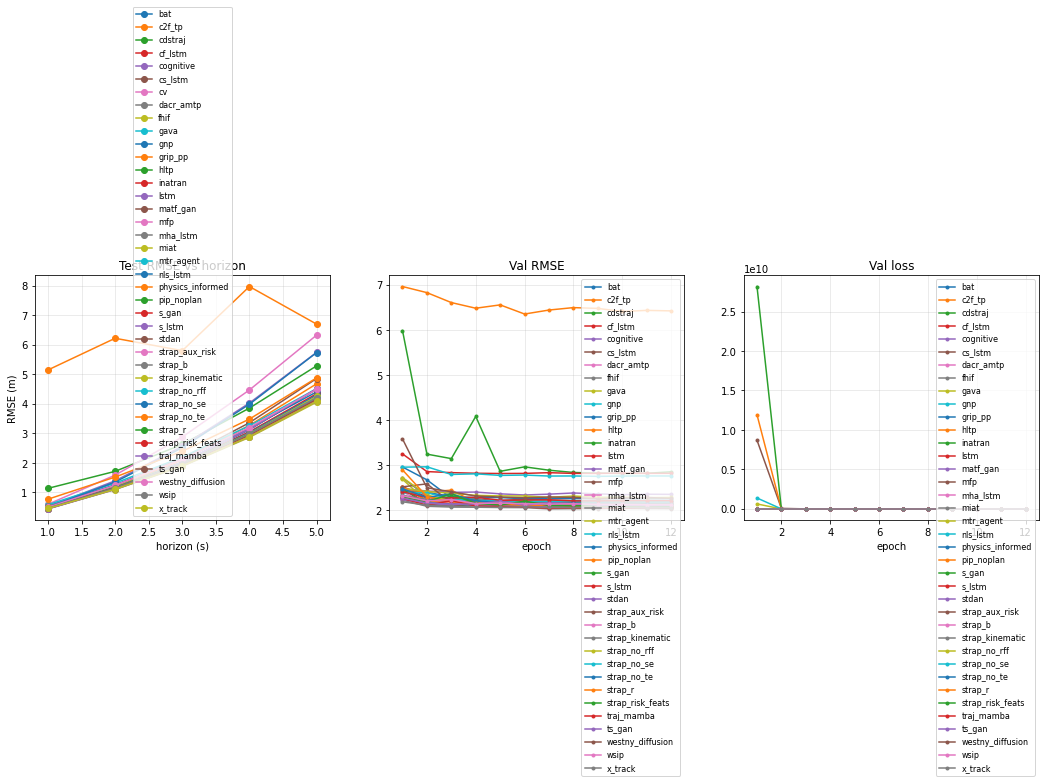

In [9]:
rmse_df, collision_df = compare()